# EC-Otyper benchmark — McNemar's test vs ECTyper and EcOH

**Data:** `benchmark_summary.csv` — 185 *E. coli* assemblies, each typed in silico by three tools
(**EC-Otyper**, **ECTyper**, **EcOH**) against a reported (reference) O-antigen.

**Questions**

1. Does EC-Otyper call the reported O-antigen **correctly** more often than ECTyper and EcOH?
2. Does EC-Otyper **fail to emit a prediction** (`No Prediction`) less often than the other two tools?

**Definitions**

- *Correct prediction* = result in `{Correct, Ambiguous Correct}` (an ambiguous match to a
  cross-referenced type is not counted as correct).
- *No prediction* = result == `No Prediction`.

**Statistics**

- Each assembly is a **paired** observation (all three tools type the same genome), so the tools
  are compared with **McNemar's test** on the discordant pairs only.
- Exact two-sided McNemar (binomial test on discordant pairs) is the primary test; the
  continuity-corrected asymptotic χ² is reported as a sensitivity check.
- Four tests are run (2 questions × 2 comparator tools), so raw *p*-values are adjusted with
  **Holm–Bonferroni** (family-wise) and **Benjamini–Hochberg FDR**; α = 0.05.


## 1. Setup

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.stats import binomtest
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CSV_PATH = "benchmark_summary.csv"
TOOLS = ["EC-Otyper", "ECTyper", "EcOH"]
OTHERS = [t for t in TOOLS if t != "EC-Otyper"]          # comparators
CORRECT = {"Correct", "Ambiguous Correct"}          # correctness definition
NO_PRED = "No Prediction"
ALPHA = 0.05


## 2. Load data

The CSV has a UTF-8 BOM, so it is read with `encoding="utf-8-sig"`.


In [2]:
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
df.columns = [c.strip() for c in df.columns]

RESULT_COLS = [f"{t} result" for t in TOOLS]
assert all(c in df.columns for c in RESULT_COLS), "missing result columns"
print(f"{len(df)} assemblies × {len(TOOLS)} tools\n")

df.head()


185 assemblies × 3 tools



,Assembly,Reported O-antigen,EC-Otyper prediction,ECTyper prediction,EcOH prediction,EC-Otyper result,ECTyper result,EcOH result
0,ESC_OB1501AA_AS,O174,Rough LPS (OL173),-,-,No Prediction,No Prediction,No Prediction
1,ESC_OB1502AA_AS,O28ac,O28ac-Gp2,O28/O42,O28ac/O42,Ambiguous Correct,Ambiguous Match,Ambiguous Match
2,ESC_OB1503AA_AS,O160,O160,-,-,Correct,No Prediction,No Prediction
3,ESC_OB1504AA_AS,O136,O136,O136,O136,Correct,Correct,Correct
4,ESC_OB1505AA_AS,O5,O5,O5,O5,Correct,Correct,Correct


In [3]:
# Raw result-category counts per tool
counts = pd.DataFrame({t: df[f"{t} result"].value_counts() for t in TOOLS}).fillna(0).astype(int)
counts = counts.reindex(columns=TOOLS)
counts


,EC-Otyper,ECTyper,EcOH
Ambiguous Correct,15,5,10
Ambiguous Match,6,15,16
Correct,161,154,154
Incorrect,2,0,1
No Prediction,1,11,4


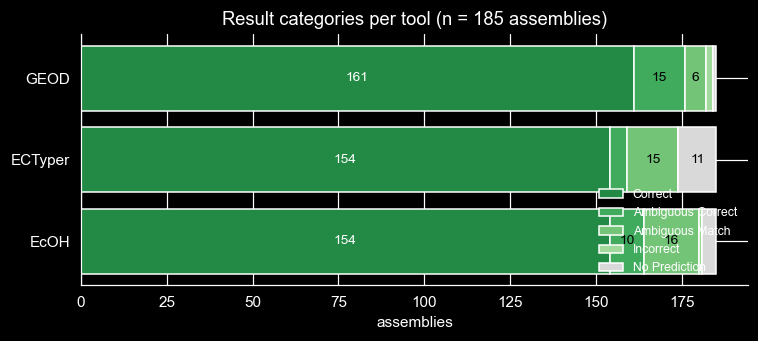

In [4]:
# Figure 1 — result-category distribution per tool
order = ["Correct", "Ambiguous Correct", "Ambiguous Match", "Incorrect", "No Prediction"]
plot_counts = counts.reindex([c for c in order if c in counts.index]).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(7, 3.2))
left = np.zeros(len(TOOLS))
greens = plt.cm.Greens(np.linspace(0.75, 0.25, len(plot_counts)))
color_map = {cat: ((0.85, 0.85, 0.85, 1.0) if cat == "No Prediction" else col)
             for cat, col in zip(plot_counts.index, greens)}
for cat, row in plot_counts.iterrows():
    ax.barh(TOOLS, row.values, left=left, label=cat, color=color_map[cat], edgecolor="white")
    left += row.values
# annotate segments
for j, tool in enumerate(TOOLS):
    y0 = 0
    for cat, x in plot_counts[tool].items():
        if x >= 6:
            ax.text(y0 + x / 2, j, str(x), ha="center", va="center",
                    fontsize=9, color="white" if cat == "Correct" else "black")
        y0 += x
ax.invert_yaxis()
ax.set_xlabel("assemblies")
ax.set_title("Result categories per tool (n = %d assemblies)" % len(df))
ax.legend(loc="lower right", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()


## 3. Binary outcome definitions and per-tool summary

For each tool two binary indicators are derived per assembly:

- `correct` — result ∈ {Correct, Ambiguous Correct}
- `no_pred` — result == No Prediction


In [5]:
ind = pd.DataFrame(index=df.index)
for t in TOOLS:
    res = df[f"{t} result"]
    ind[f"{t}__correct"] = res.isin(CORRECT)
    ind[f"{t}__no_pred"] = res == NO_PRED

summary = pd.DataFrame({
    "correct": ind[[f"{t}__correct" for t in TOOLS]].sum().values,
    "no_pred": ind[[f"{t}__no_pred" for t in TOOLS]].sum().values,
}, index=TOOLS)
summary["correct %"] = 100 * summary["correct"] / len(df)
summary["no_pred %"] = 100 * summary["no_pred"] / len(df)
summary


,correct,no_pred,correct %,no_pred %
EC-Otyper,176,1,95.1351,0.5405
ECTyper,159,11,85.9459,5.9459
EcOH,164,4,88.6486,2.1622


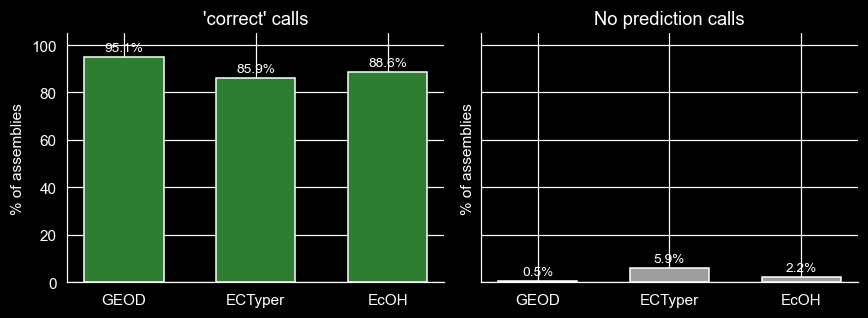

In [6]:
# Figure 2 — correct vs no-prediction rates per tool
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for ax, col, color in zip(axes, ["correct", "no_pred"], ["#2e7d32", "#9e9e9e"]):
    rates = 100 * summary[col] / len(df)
    bars = ax.bar(rates.index, rates.values, color=color, width=0.6)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=9, padding=2)
    ax.set_title(f"'{col}' calls" if col == "correct" else "No prediction calls")
    ax.set_ylabel("% of assemblies")
    ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()


## 4. Paired 2×2 tables and exact McNemar's test

For each EC-Otyper-vs-tool comparison a paired 2×2 table is built over the 185 assemblies:

|  | comparator **positive** | comparator **negative** |
|---|---|---|
| **EC-Otyper positive** | *a* (both) | ***b*** (EC-Otyper only) |
| **EC-Otyper negative** | ***c*** (comparator only) | *d* (neither) |

"Positive" = *correct* (or *made a prediction*, i.e. not `No Prediction`) depending on the
comparison. McNemar's test uses only the **discordant** cells *b* and *c*; the exact two-sided
*p*-value comes from `scipy.stats.binomtest(min(b, c), b + c, 0.5)`.

Comparisons run (4 in total, so a multiple-comparison correction is required):

1. EC-Otyper **correct** vs ECTyper correct
2. EC-Otyper **correct** vs EcOH correct
3. EC-Otyper **no-prediction** vs ECTyper no-prediction
4. EC-Otyper **no-prediction** vs EcOH no-prediction


In [7]:
def mcnemar_row(ecotyper_pos, other_pos, label):
    """Paired 2x2 table + exact McNemar test for one EC-Otyper-vs-tool comparison."""
    a = int(( ecotyper_pos &  other_pos).sum())   # both positive
    b = int(( ecotyper_pos & ~other_pos).sum())   # EC-Otyper only   (discordant)
    c = int((~ecotyper_pos &  other_pos).sum())   # other only  (discordant)
    d = int((~ecotyper_pos & ~other_pos).sum())   # neither
    table = np.array([[a, b], [c, d]])

    n_disc = b + c
    if n_disc == 0:                                  # perfect agreement
        p_exact, p_cc = 1.0, 1.0
    else:
        p_exact = binomtest(min(b, c), n_disc, 0.5, alternative="two-sided").pvalue
        # sensitivity check: continuity-corrected asymptotic chi-square
        stat = (abs(b - c) - 1) ** 2 / (b + c)
        p_cc = float(mcnemar(table, exact=False, correction=True).pvalue)

    return {
        "comparison": label,
        "a both+": a, "b EC-Otyper-only": b, "c other-only": c, "d both-": d,
        "discordant n": n_disc,
        "EC-Otyper rate %": 100 * ecotyper_pos.mean(),
        "other rate %": 100 * other_pos.mean(),
        "odds ratio (b/c)": np.inf if (b > 0 and c == 0) else (b / c if c else np.nan),
        "p (exact McNemar)": p_exact,
        "p (chi2, cc)": p_cc,
    }

rows = []
for outcome, suffix in [("correct", "__correct"), ("no_pred", "__no_pred")]:
    for other in OTHERS:
        rows.append(mcnemar_row(
            ind[f"EC-Otyper{suffix}"], ind[f"{other}{suffix}"],
            f"EC-Otyper {outcome} vs {other} {outcome}",
        ))
res = pd.DataFrame(rows)
res


,comparison,a both+,b EC-Otyper-only,c other-only,d both-,discordant n,EC-Otyper rate %,other rate %,odds ratio (b/c),p (exact McNemar),"p (chi2, cc)"
0,EC-Otyper correct vs ECTyper correct,157,19,2,7,21,95.1351,85.9459,9.5,0.0002,0.0005
1,EC-Otyper correct vs EcOH correct,163,13,1,8,14,95.1351,88.6486,13.0,0.0018,0.0033
2,EC-Otyper no_pred vs ECTyper no_pred,1,0,10,174,10,0.5405,5.9459,0.0,0.0020,0.0044
3,EC-Otyper no_pred vs EcOH no_pred,1,0,3,181,3,0.5405,2.1622,0.0,0.2500,0.2482


## 5. Multiple-comparisons correction

The four *p*-values from the exact McNemar tests are adjusted with:

- **Holm–Bonferroni** (controls family-wise error rate) — primary,
- **Benjamini–Hochberg** (controls false discovery rate) — shown for reference.


In [8]:
adj = multipletests(res["p (exact McNemar)"].values, alpha=ALPHA, method="holm")
res["p (Holm adj.)"] = adj[1]
res["significant (Holm)"] = adj[0]

bh = multipletests(res["p (exact McNemar)"].values, alpha=ALPHA, method="fdr_bh")
res["p (BH-FDR adj.)"] = bh[1]
res["significant (BH)"] = bh[0]

res[[
    "comparison", "b EC-Otyper-only", "c other-only", "discordant n",
    "EC-Otyper rate %", "other rate %",
    "p (exact McNemar)", "p (Holm adj.)", "significant (Holm)",
    "p (BH-FDR adj.)", "significant (BH)",
]]


,comparison,b EC-Otyper-only,c other-only,discordant n,EC-Otyper rate %,other rate %,p (exact McNemar),p (Holm adj.),significant (Holm),p (BH-FDR adj.),significant (BH)
0,EC-Otyper correct vs ECTyper correct,19,2,21,95.1351,85.9459,0.0002,0.0009,True,0.0009,True
1,EC-Otyper correct vs EcOH correct,13,1,14,95.1351,88.6486,0.0018,0.0055,True,0.0026,True
2,EC-Otyper no_pred vs ECTyper no_pred,0,10,10,0.5405,5.9459,0.0020,0.0055,True,0.0026,True
3,EC-Otyper no_pred vs EcOH no_pred,0,3,3,0.5405,2.1622,0.2500,0.2500,False,0.2500,False


## 6. Discordance structure of the McNemar tables

Each panel shows one paired 2×2 table; the shaded off-diagonal cells are the discordant pairs
that drive McNemar's test.


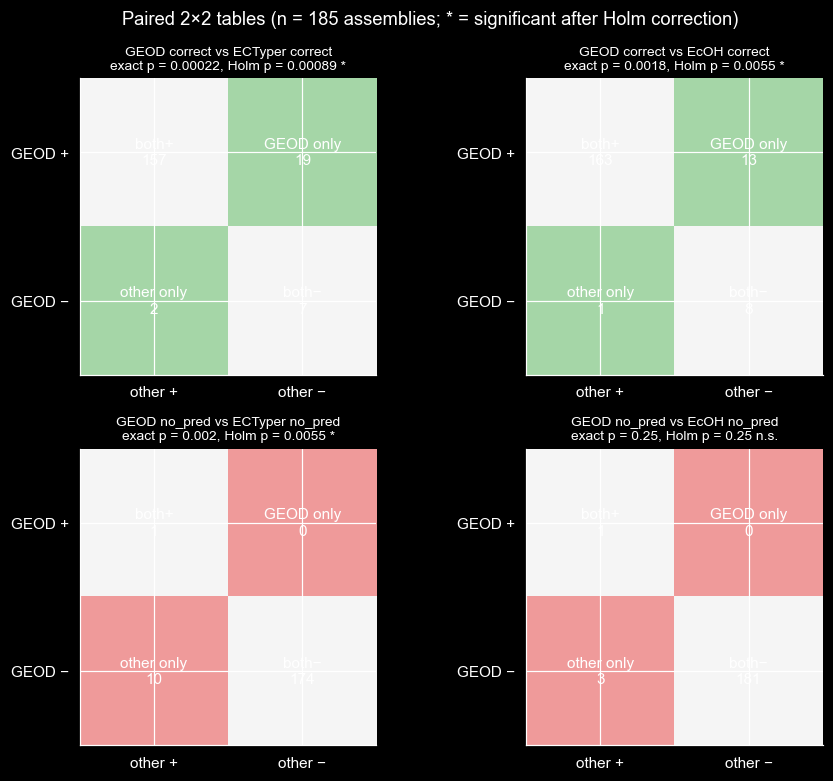

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(8.5, 7.2))
cmap = ListedColormap(["#f5f5f5", "#a5d6a7", "#ef9a9a"])

for ax, (_, row) in zip(axes.flat, res.iterrows()):
    tab = np.array([[row["a both+"], row["b EC-Otyper-only"]],
                    [row["c other-only"], row["d both-"]]], dtype=float)
    disc = np.array([[False, True], [True, False]])
    shade = np.where(disc, 1, 0)                       # 1 = discordant cell
    ecotyper_fav = (row["b EC-Otyper-only"] > row["c other-only"])
    shade = np.where(disc, 1 if ecotyper_fav else 2, 0)    # green = EC-Otyper wins, red = loses

    ax.imshow(shade, cmap=cmap, vmin=0, vmax=2)
    labels = [[f"both+\n{int(tab[0,0])}", f"EC-Otyper only\n{int(tab[0,1])}"],
              [f"other only\n{int(tab[1,0])}", f"both−\n{int(tab[1,1])}"]]
    for (i, j), txt in np.ndenumerate(labels):
        ax.text(j, i, txt, ha="center", va="center", fontsize=10)
    ax.set_xticks([0, 1], ["other +", "other −"])
    ax.set_yticks([0, 1], ["EC-Otyper +", "EC-Otyper −"])
    p_h = row["p (Holm adj.)"]
    star = " *" if row["significant (Holm)"] else " n.s."
    ax.set_title(f"{row['comparison']}\nexact p = {row['p (exact McNemar)']:.2g}, "
                 f"Holm p = {p_h:.2g}{star}", fontsize=9)
fig.suptitle("Paired 2×2 tables (n = %d assemblies; * = significant after Holm correction)" % len(df),
             y=0.98)
plt.tight_layout()
plt.show()


## 7. Export

In [10]:
out = res.copy()
out.to_csv("mcnemar_results.csv", index=False)
print("wrote mcnemar_results.csv")
out[["comparison", "b EC-Otyper-only", "c other-only", "p (exact McNemar)",
     "p (Holm adj.)", "significant (Holm)"]]


wrote mcnemar_results.csv


,comparison,b EC-Otyper-only,c other-only,p (exact McNemar),p (Holm adj.),significant (Holm)
0,EC-Otyper correct vs ECTyper correct,19,2,0.0002,0.0009,True
1,EC-Otyper correct vs EcOH correct,13,1,0.0018,0.0055,True
2,EC-Otyper no_pred vs ECTyper no_pred,0,10,0.0020,0.0055,True
3,EC-Otyper no_pred vs EcOH no_pred,0,3,0.2500,0.2500,False


## 8. Interpretation

**Correct O-antigen calls** — EC-Otyper was correct on **176/185** assemblies (95.1%), versus
**159/185** (85.9%) for ECTyper and **164/185** (88.6%) for EcOH. Both differences are driven by
the discordant pairs (19 vs 2 for ECTyper, 13 vs 1 for EcOH) and remain significant after Holm–Bonferroni
correction across the four tests (exact *p* = 2.2 × 10⁻⁴ and 1.8 × 10⁻³; Holm-adjusted
*p* = 8.9 × 10⁻⁴ and 5.5 × 10⁻³). EC-Otyper therefore recovers the reported O-antigen significantly
more often than either comparator.

**No-prediction calls** — EC-Otyper failed to emit any prediction for only **1/185** assembly (0.5%),
against **11/185** (5.9%) for ECTyper and **4/185** (2.2%) for EcOH. The shortfall vs ECTyper is
significant (10 vs 0 discordant pairs; exact *p* = 2.0 × 10⁻³, Holm-adjusted *p* = 5.5 × 10⁻³),
but the difference vs EcOH (3 vs 0) is not (exact *p* = 0.25), so EC-Otyper and EcOH are statistically
indistinguishable on this measure with this sample size.

**Caveats**

- McNemar's exact test has little power when the discordant count is small (e.g. 3 pairs vs EcOH);
  absence of significance ≠ equivalence.
- Each assembly is treated as an independent paired observation; if assemblies share strains or
  clonal background, a cluster-robust (e.g. stratified or permutation) analysis would be needed.
- "Correct" here counts `Ambiguous Correct` as a success, per the analysis definition.
